# PT-02 - Análise Exploratória do dataset Wine

**Aluno:** Valentim S. A. Neto  
**Matrícula:** 2019027210  
**Disciplina:** Aprendizado de Máquina

## Objetivo

Investigar as 13 variáveis de entrada do dataset Wine, procurando características
redundantes ou pouco informativas por meio de estatística descritiva, correlações,
scatterplots e boxplots. O notebook funciona como uma análise reproduzível; as
interpretações consolidadas também aparecem no relatório em PDF.

## 1. Carregamento e identificação das variáveis

A documentação do `load_wine` informa 178 amostras, 13 entradas numéricas positivas
e três classes. A saída `target` codifica as classes 0, 1 e 2 (`class_0`, `class_1`
e `class_2`). Abaixo carregamos os dados diretamente do scikit-learn.

Fonte: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

sns.set_theme(style="whitegrid", context="notebook")
wine_data = load_wine()
df = pd.DataFrame(wine_data.data, columns=wine_data.feature_names)
df["target"] = wine_data.target

print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Entradas:", ", ".join(wine_data.feature_names))
print("Saída: target ->", dict(enumerate(wine_data.target_names)))
df.head()

Dimensões: 178 linhas x 14 colunas
Entradas: alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline
Saída: target -> {0: np.str_('class_0'), 1: np.str_('class_1'), 2: np.str_('class_2')}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


**Interpretação.** Cada linha representa uma amostra de vinho. As entradas são:
`alcohol`, `malic_acid`, `ash`, `alcalinity_of_ash`, `magnesium`,
`total_phenols`, `flavanoids`, `nonflavanoid_phenols`, `proanthocyanins`,
`color_intensity`, `hue`, `od280/od315_of_diluted_wines` e `proline`.
A saída é `target`, uma classe categórica com três valores.

## 2. Descrição estatística

`describe()` resume contagem, média, desvio-padrão, quartis, mínimo e máximo.

In [2]:
resumo = df.drop(columns="target").describe().T
resumo.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


**Interpretação.** Todas as entradas têm 178 observações, portanto não há valores
ausentes. As escalas são muito diferentes: `proline` chega a 1.680, enquanto
outras variáveis ficam próximas de zero. Essa diferença não invalida a AED, mas
exigiria padronização antes de muitos algoritmos baseados em distância.

In [3]:
assert df.shape == (178, 14)
assert df.isna().sum().sum() == 0
assert set(df["target"].unique()) == {0, 1, 2}
assert (df.drop(columns="target") > 0).all().all()
print("Validações concluídas: dimensões, ausência de nulos, classes e positividade.")

Validações concluídas: dimensões, ausência de nulos, classes e positividade.


## 3. Matriz de correlações

A correlação de Pearson mede relações lineares. Consideraremos forte uma relação com $|r| \geq 0{,}80$.

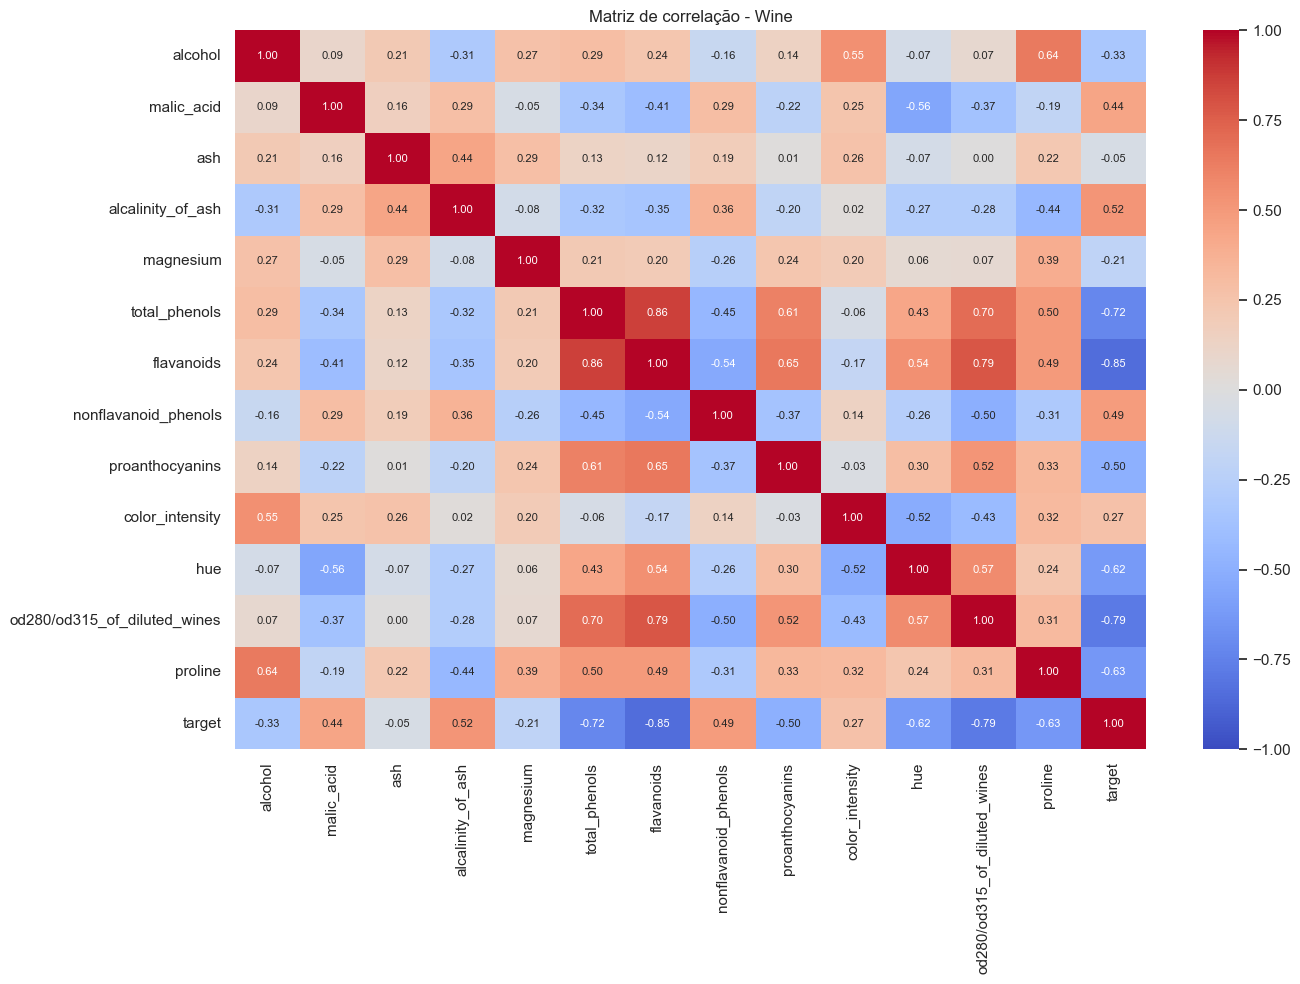

In [4]:
correlacoes = df.corr(numeric_only=True)
plt.figure(figsize=(14, 10))
sns.heatmap(correlacoes, annot=True, cmap="coolwarm", center=0,
            vmin=-1, vmax=1, fmt=".2f", annot_kws={"size": 8})
plt.title("Matriz de correlação - Wine")
plt.tight_layout()
plt.show()

**Interpretação.** Entre as entradas, apenas `total_phenols` e `flavanoids`
ultrapassam o limiar do enunciado, com **r = 0.865**.
Elas carregam informação linear bastante semelhante e formam o principal caso de
redundância. A correlação com `target` ajuda a interpretar associação, mas o alvo é
categórico e seus códigos são ordinais apenas por convenção; portanto, ela não deve
ser tratada isoladamente como medida definitiva de relevância.

## 4. Matriz de scatterplots

A cor identifica as classes. A diagonal mostra a distribuição de cada entrada.

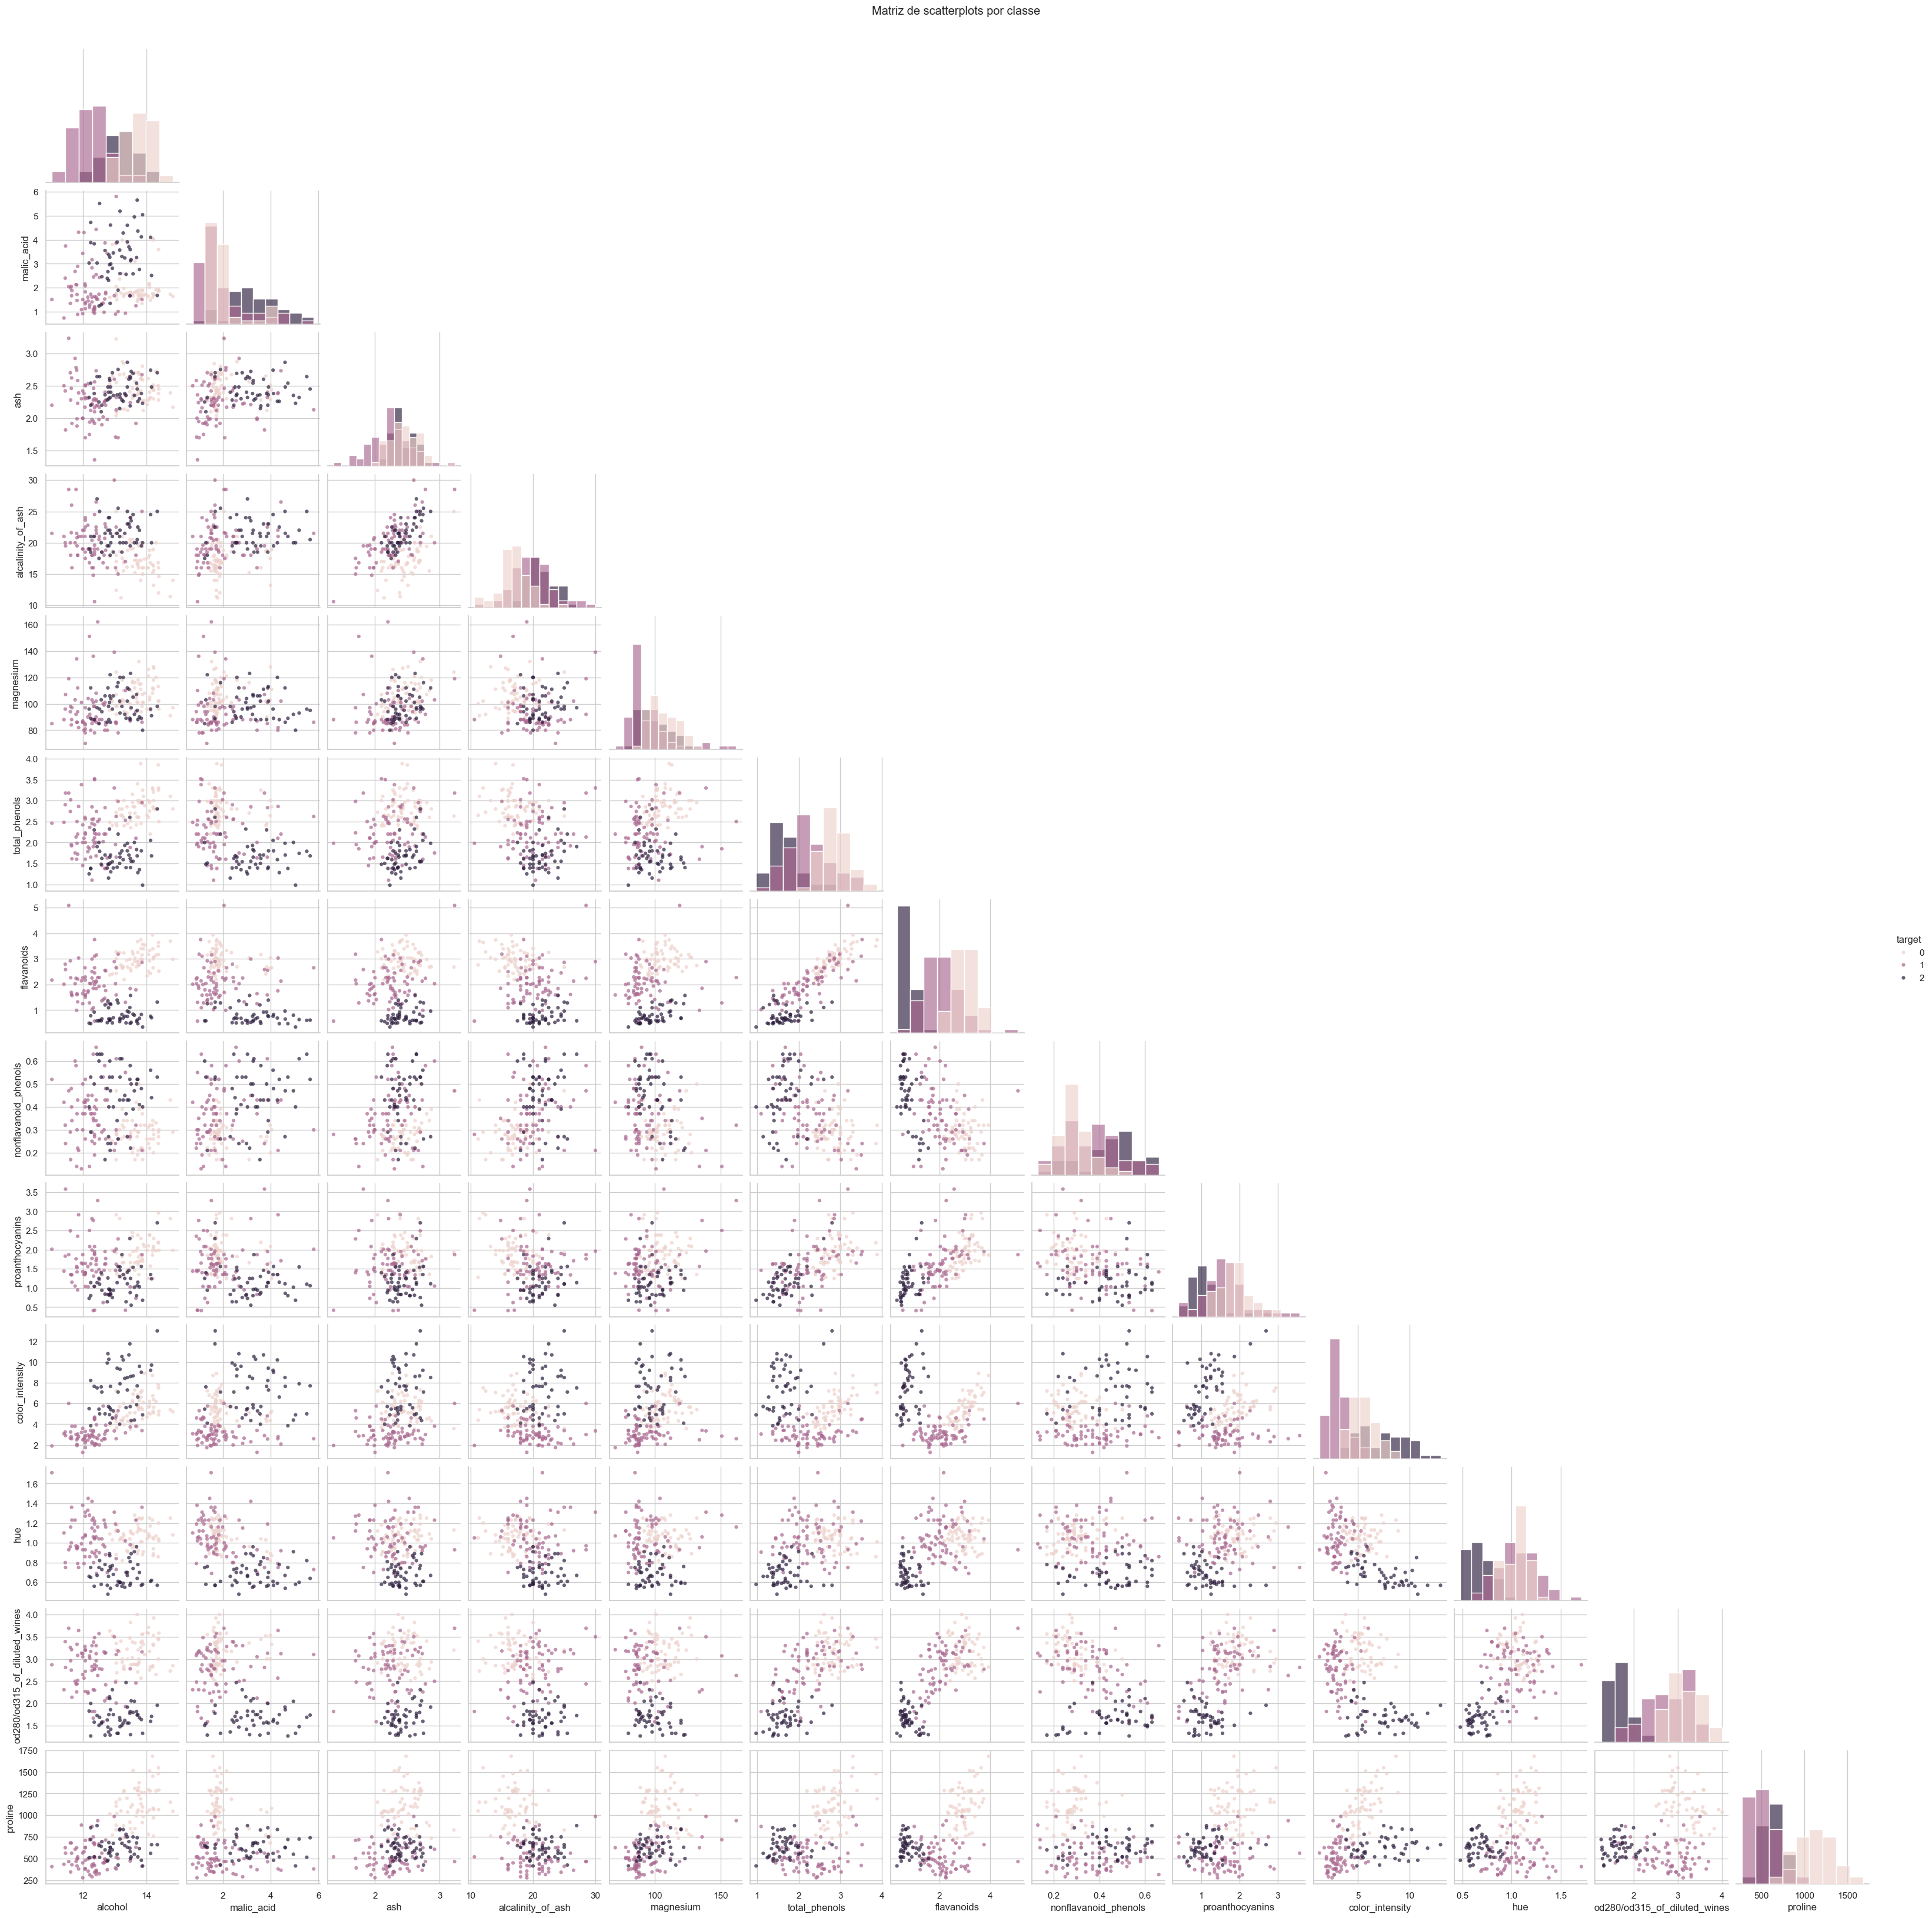

In [5]:
pairplot = sns.pairplot(
    df, hue="target", diag_kind="hist", corner=True,
    plot_kws={"alpha": 0.70, "s": 20, "edgecolor": "none"},
    diag_kws={"alpha": 0.65},
)
pairplot.fig.suptitle("Matriz de scatterplots por classe", y=1.01)
plt.show()

**Interpretação.** `flavanoids`, `od280/od315_of_diluted_wines`, `proline`,
`color_intensity` e `alcohol` mostram separações visuais úteis em diferentes
classes. `total_phenols` acompanha fortemente `flavanoids`, reforçando a
redundância. `ash`, isoladamente, apresenta ampla sobreposição entre as três
classes; `magnesium` também tem sobreposição considerável. Nenhuma variável,
sozinha, separa perfeitamente todas as classes.

## 5. Boxplots individuais e outliers

Cada variável possui escala própria; por isso, cada boxplot é exibido em um gráfico
separado. Isso evita que `proline` comprima visualmente as demais distribuições.

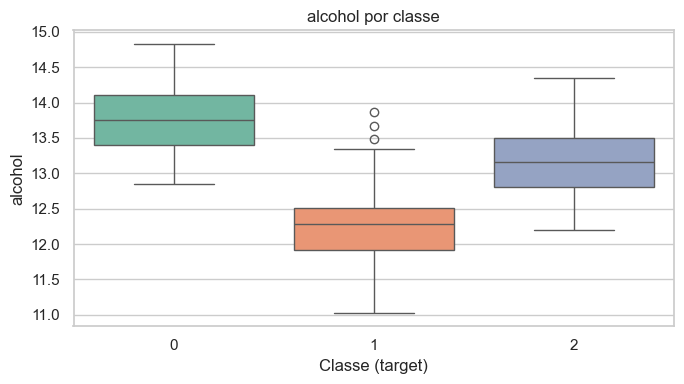

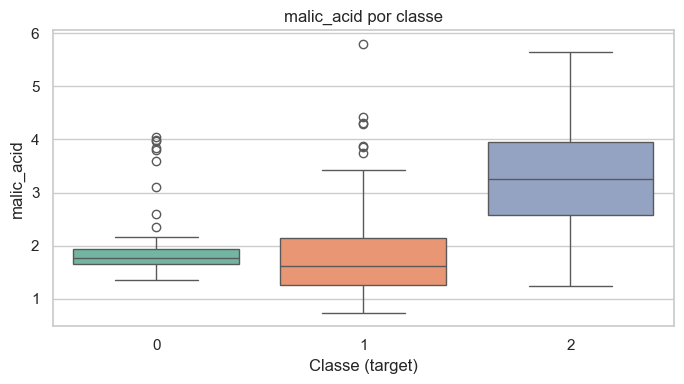

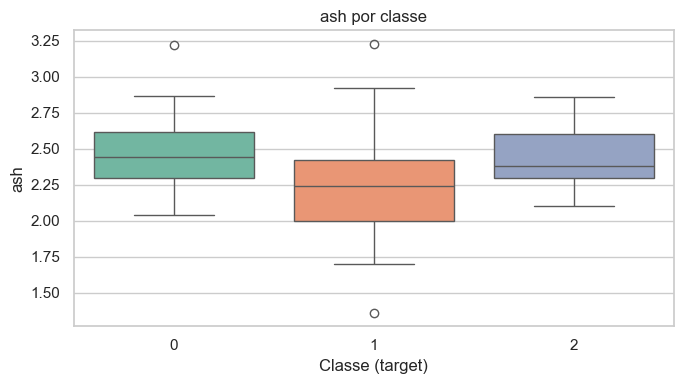

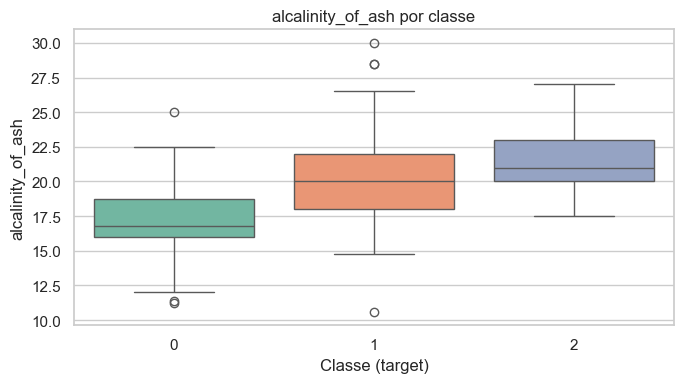

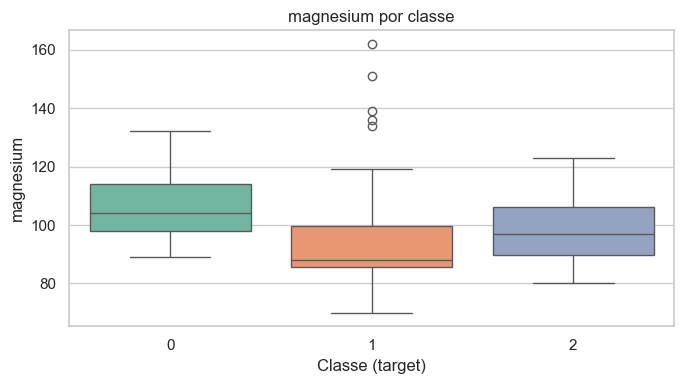

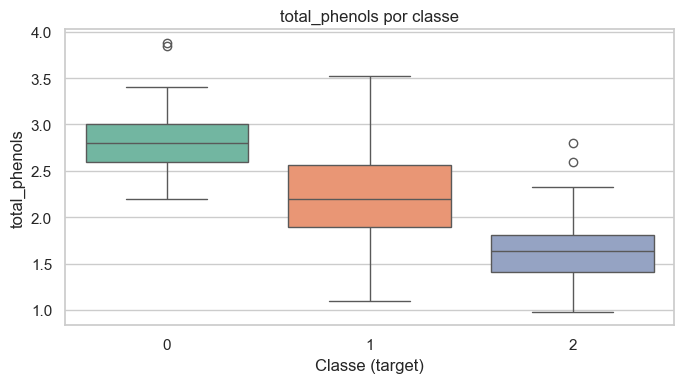

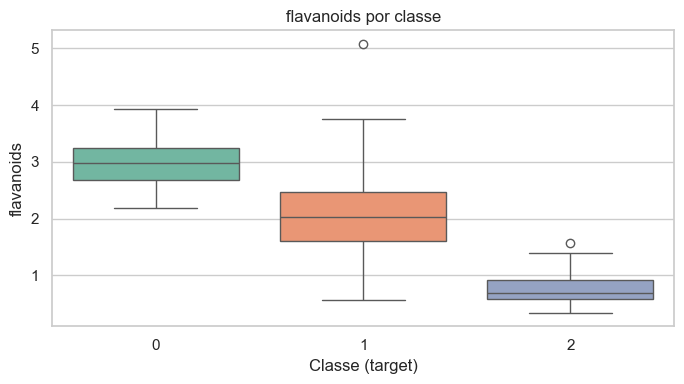

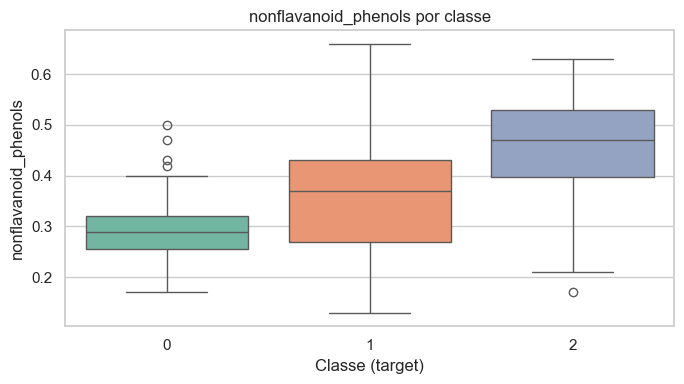

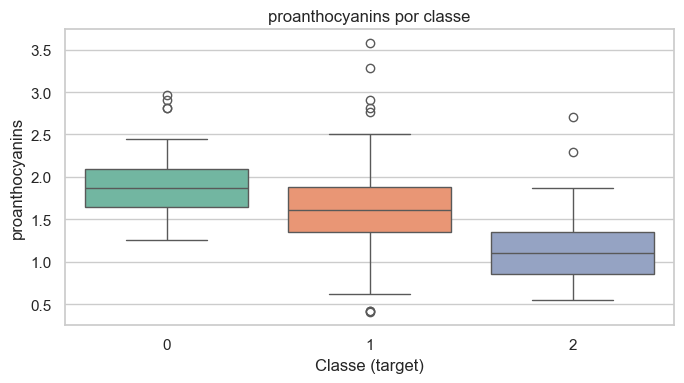

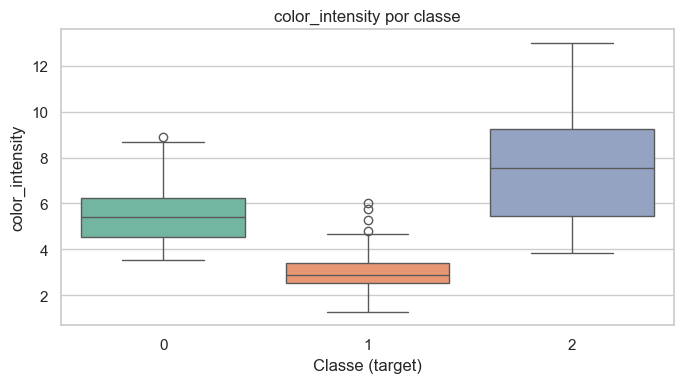

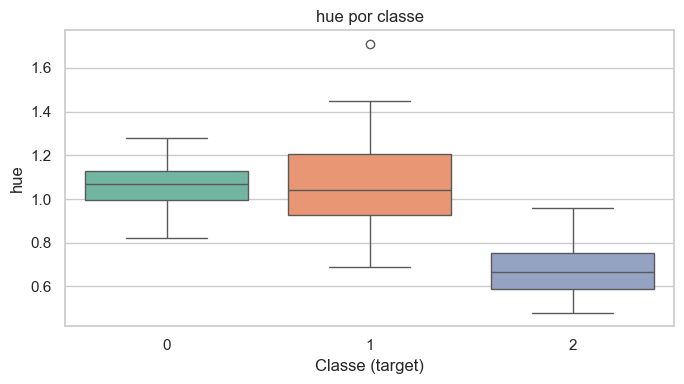

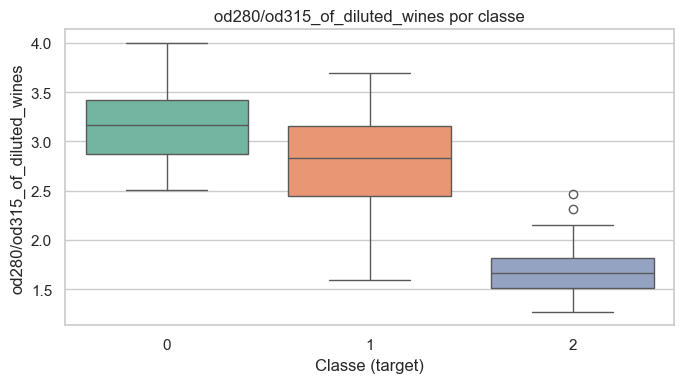

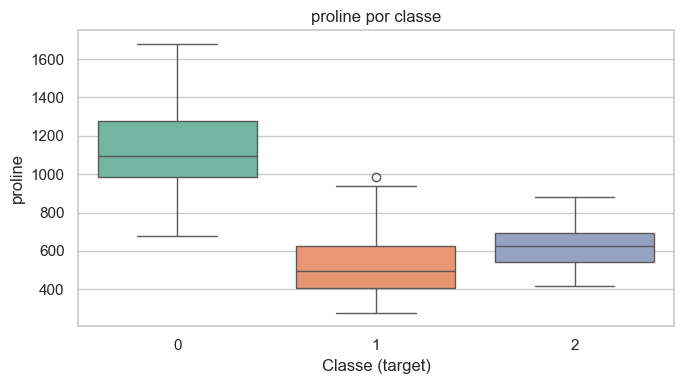

,outliers_IQR
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
nonflavanoid_phenols,0


In [6]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

contagem_outliers = {}
for feature in wine_data.feature_names:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.boxplot(data=df, x="target", y=feature, hue="target",
                palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{feature} por classe")
    ax.set_xlabel("Classe (target)")
    ax.set_ylabel(feature)
    plt.tight_layout()
    plt.show()
    contagem_outliers[feature] = contar_outliers_iqr(df[feature])

pd.Series(contagem_outliers, name="outliers_IQR").sort_values(ascending=False).to_frame()

**Interpretação.** Pelo critério global de Tukey (1,5 vezes o intervalo
interquartil), há observações atípicas em: malic_acid (3), ash (3), alcalinity_of_ash (4), magnesium (4), proanthocyanins (2), color_intensity (4), hue (1). Um ponto fora dos
limites do boxplot não é automaticamente erro e não foi removido. As distribuições
de `ash` são muito sobrepostas; `magnesium` também discrimina pouco isoladamente.
Já `flavanoids`, `od280/od315_of_diluted_wines`, `proline`, `color_intensity` e
`alcohol` apresentam deslocamentos claros entre pelo menos algumas classes.

## 6. Conclusão

1. **Variáveis altamente correlacionadas:** `total_phenols` e `flavanoids`
   (r = 0.865). A semelhança linear e visual
   indica informação parcialmente duplicada.
2. **Possíveis variáveis pouco relevantes:** `ash` é a candidata mais forte devido
   à grande sobreposição entre classes. `magnesium` também tem separação limitada,
   embora ainda possa contribuir em combinação com outras entradas.
3. **Candidatas à remoção:** eu testaria retirar `total_phenols`, mantendo
   `flavanoids`, e avaliaria `ash` por validação cruzada. `magnesium` seria uma
   candidata secundária, não uma remoção automática.

Essas decisões são hipóteses de AED, não uma seleção definitiva. O passo correto
antes de otimizar um classificador é comparar, por validação cruzada, o desempenho
com todas as entradas e com cada conjunto reduzido. Correlação não implica que uma
variável seja inútil, e sobreposição univariada não elimina interações multivariadas.